# Analyse bivariée : numérique × numérique

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/KTFGHU14.csv", sep=";")

# FirstPur est une date : on la transforme en nombre (ancienneté en mois)
dates = pd.to_datetime(df["FirstPur"], format="%d/%m/%Y")
df["Anciennete"] = (pd.Timestamp("2014-05-01") - dates).dt.days / 30.44

var_num = ["Age", "TotalSpent", "TotalPur", "LastPur", "Anciennete",
           "NovelPur", "ChildPur", "YouthPur", "CookPur", "DiyPur", "RefPur",
           "ArtPur", "GeogPur", "ProvCook", "ProvAtlas", "ProvArt", "RelPur"]

print(len(var_num), "variables numériques")

17 variables numériques


## 1. Corrélation de Pearson

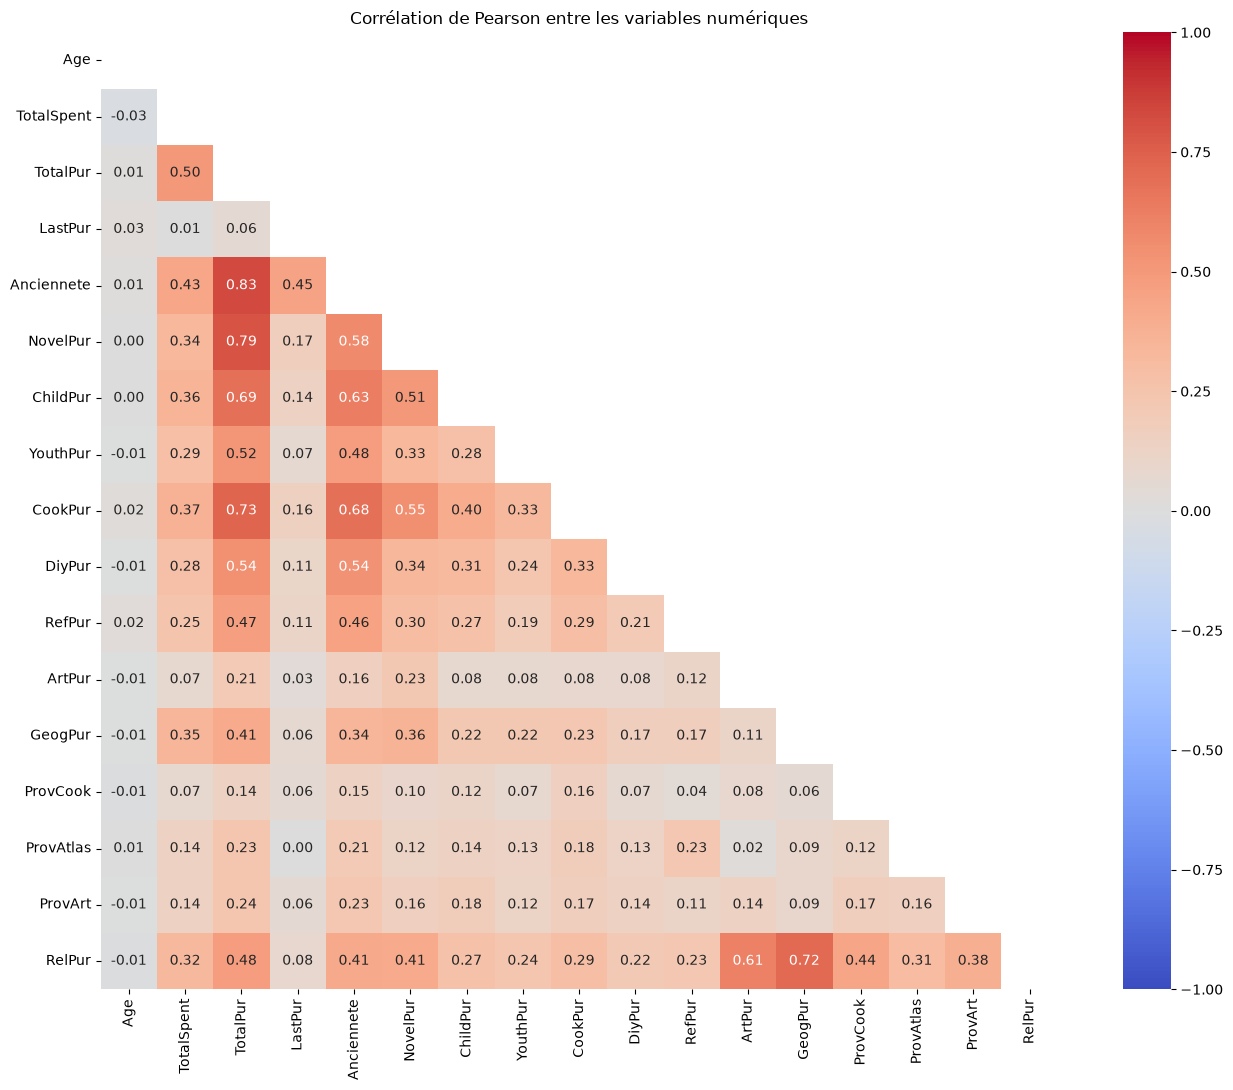

In [2]:
corr_pearson = df[var_num].corr(method="pearson")

# on cache la moitié haute (elle répète la moitié basse)
masque = np.triu(np.ones_like(corr_pearson, dtype=bool))

plt.figure(figsize=(14, 11))
sns.heatmap(corr_pearson, mask=masque, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélation de Pearson entre les variables numériques")
plt.tight_layout()
plt.savefig("figures/corr_pearson.png")
plt.show()

In [3]:
paires = corr_pearson.where(~masque).stack()          # garde chaque paire une seule fois
paires = paires.reindex(paires.abs().sort_values(ascending=False).index)
paires.head(15).round(2)

Anciennete  TotalPur      0.83
NovelPur    TotalPur      0.79
CookPur     TotalPur      0.73
RelPur      GeogPur       0.72
ChildPur    TotalPur      0.69
CookPur     Anciennete    0.68
ChildPur    Anciennete    0.63
RelPur      ArtPur        0.61
NovelPur    Anciennete    0.58
CookPur     NovelPur      0.55
DiyPur      TotalPur      0.54
            Anciennete    0.54
YouthPur    TotalPur      0.52
ChildPur    NovelPur      0.51
TotalPur    TotalSpent    0.50
dtype: float64

**Ce qu'on voit :**
- Age n'est lié à aucune autre variable (corrélations proches de 0).
- Aucune corrélation négative.
- Lien le plus fort : TotalPur × Anciennete (0,83). Les clients anciens ont acheté plus de livres.
- TotalPur est fortement lié aux catégories : NovelPur (0,79), CookPur (0,73), ChildPur (0,69).
- RelPur est liée à GeogPur (0,72), ArtPur (0,61) et aux livres Provence.
- TotalSpent × TotalPur n'est que de 0,50 : plus de livres ne veut pas toujours dire plus d'argent dépensé.
- Les livres Provence (ProvCook, ProvAtlas, ProvArt) sont peu liés aux autres variables (< 0,25).

**Ce que ça veut dire :**
- L'hypothèse de la S1 est fausse : les deux groupes d'âge ne correspondent pas aux petits et gros acheteurs.
- TotalPur et RelPur sont redondantes : elles répètent l'information des catégories (confirme la S1).
- Le lien moyen entre TotalSpent et TotalPur confirme les incohérences trouvées en S1 (prix par livre bizarres, TotalPur faux pour ~395 clients).
- Les livres Provence apportent une information à part : ils pourraient être utiles pour prédire ProvPur.

**À faire en S3 :** supprimer RelPur, corriger ou supprimer TotalPur.

### Spearman

In [4]:
corr_spearman = df[var_num].corr(method="spearman")

difference = (corr_spearman - corr_pearson).where(~masque).stack()
difference = difference.reindex(difference.abs().sort_values(ascending=False).index)

print("Plus grande différence entre Spearman et Pearson :", round(difference.abs().max(), 2))
difference.head(5).round(2)

Plus grande différence entre Spearman et Pearson : 0.09


RelPur      ProvArt      -0.09
TotalPur    TotalSpent   -0.07
CookPur     NovelPur     -0.07
            TotalPur     -0.07
Anciennete  LastPur       0.06
dtype: float64

## 3. Nuages de points des paires importantes

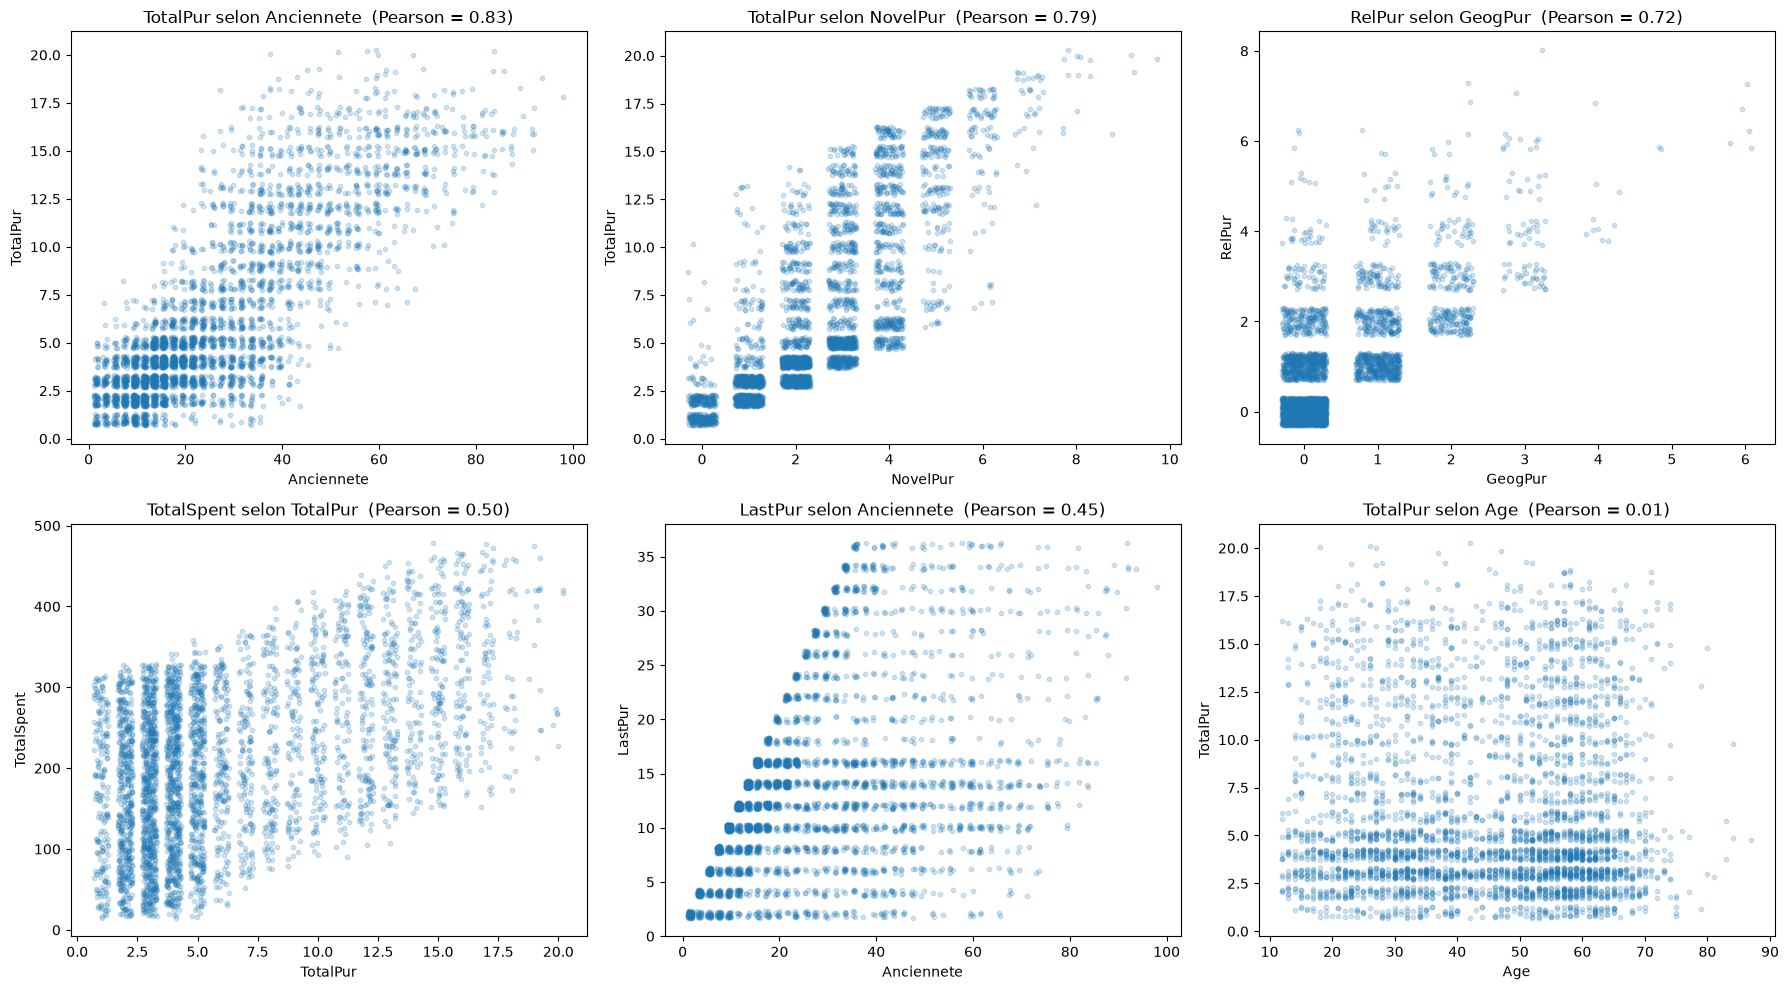

In [5]:
paires_choisies = [
    ("Anciennete", "TotalPur"),
    ("NovelPur", "TotalPur"),
    ("GeogPur", "RelPur"),
    ("TotalPur", "TotalSpent"),
    ("Anciennete", "LastPur"),
    ("Age", "TotalPur"),
]

rng = np.random.default_rng(42)          # graine fixe → même graphique à chaque lancement

def jitter(serie):
    """Petit décalage aléatoire, seulement pour l'affichage des valeurs entières."""
    if serie.nunique() < 40:
        return serie + rng.uniform(-0.3, 0.3, len(serie))
    return serie

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (x, y) in zip(axes.flat, paires_choisies):
    ax.scatter(jitter(df[x]), jitter(df[y]), alpha=0.2, s=10)
    r = df[x].corr(df[y])
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{y} selon {x}  (Pearson = {r:.2f})")

plt.tight_layout()
plt.savefig("figures/nuages_points.png")
plt.show()